In [30]:
pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
train=pd.read_csv("../data/raw/train.csv")
test=pd.read_csv("../data/raw/test.csv")

print(train.shape)
print(test.shape)

train.head()
test.head()

(1168, 81)
(292, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,893,20,RL,70.0,8414,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,2,2006,WD,Normal
1,1106,60,RL,98.0,12256,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
2,414,30,RM,56.0,8960,Pave,Grvl,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,3,2010,WD,Normal
3,523,50,RM,50.0,5000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,10,2006,WD,Normal
4,1037,20,RL,89.0,12898,Pave,NaN,IR1,HLS,AllPub,...,0,0,NaN,NaN,NaN,0,9,2009,WD,Normal


In [13]:
train.columns.tolist()
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   str    
 3   LotFrontage    951 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   str    
 6   Alley          74 non-null     str    
 7   LotShape       1168 non-null   str    
 8   LandContour    1168 non-null   str    
 9   Utilities      1168 non-null   str    
 10  LotConfig      1168 non-null   str    
 11  LandSlope      1168 non-null   str    
 12  Neighborhood   1168 non-null   str    
 13  Condition1     1168 non-null   str    
 14  Condition2     1168 non-null   str    
 15  BldgType       1168 non-null   str    
 16  HouseStyle     1168 non-null   str    
 17  OverallQual    1168 non-null   int64  
 18  OverallCond    1168

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1168.000000,1168.000000,951.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1162.000000,1168.000000,...,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,730.904966,56.849315,70.343849,10689.642123,6.121575,5.584760,1970.965753,1984.897260,103.771945,446.023973,...,95.946918,49.578767,21.839041,3.812500,15.407534,2.955479,51.267123,6.356164,2007.818493,181441.541952
std,425.369088,42.531862,24.897021,10759.366198,1.367619,1.116062,30.675495,20.733955,173.032238,459.070977,...,129.685939,69.433580,62.083227,31.519664,55.881148,41.648504,553.039684,2.670707,1.322639,77263.583862
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.750000,20.000000,59.000000,7587.250000,5.000000,5.000000,1953.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130000.000000
50%,732.500000,50.000000,70.000000,9600.000000,6.000000,5.000000,1972.000000,1994.000000,0.000000,384.500000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165000.000000
75%,1101.750000,70.000000,80.000000,11700.000000,7.000000,6.000000,2001.000000,2004.000000,166.000000,721.000000,...,168.000000,74.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214925.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1378.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,745000.000000


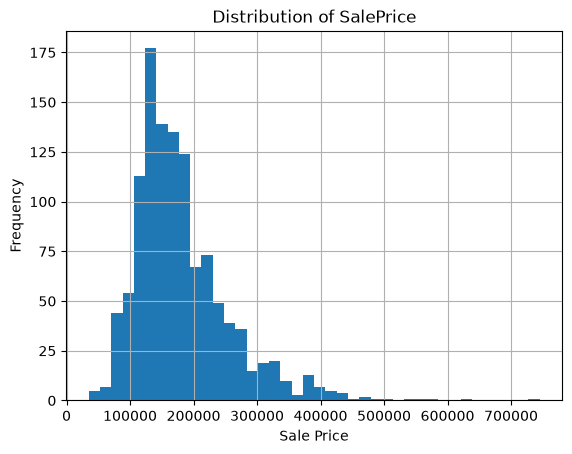

In [14]:
train["SalePrice"].hist(bins=40)

plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.title("Distribution of SalePrice")

plt.show()

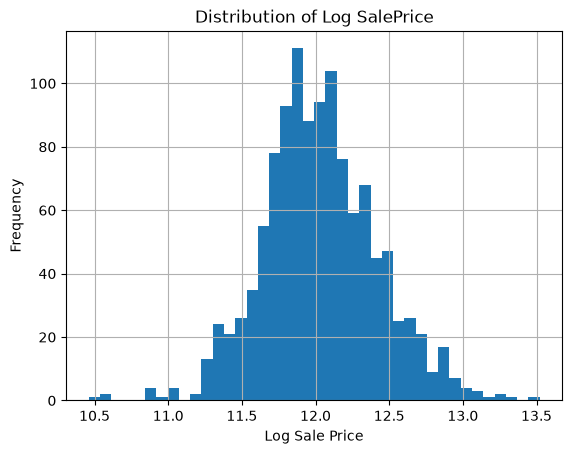

In [16]:
train["SalePrice_log"] = np.log1p(train["SalePrice"])

train["SalePrice_log"].hist(bins=40)

plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")
plt.title("Distribution of Log SalePrice")

plt.show()

Fing missing values

In [17]:
missing= (train.isnull().sum().sort_values(ascending=False))

print(missing[missing>0])

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
LotFrontage      217
GarageQual        64
GarageYrBlt       64
GarageFinish      64
GarageType        64
GarageCond        64
BsmtCond          28
BsmtFinType1      28
BsmtFinType2      28
BsmtExposure      28
BsmtQual          28
MasVnrArea         6
Electrical         1
dtype: int64


In [18]:
missing_percentage= (train.isnull().mean()*100).sort_values(ascending=False)

print(missing_percentage[missing_percentage>0])

PoolQC          99.486301
MiscFeature     96.061644
Alley           93.664384
Fence           80.051370
MasVnrType      58.476027
FireplaceQu     46.832192
LotFrontage     18.578767
GarageQual       5.479452
GarageYrBlt      5.479452
GarageFinish     5.479452
GarageType       5.479452
GarageCond       5.479452
BsmtCond         2.397260
BsmtFinType1     2.397260
BsmtFinType2     2.397260
BsmtExposure     2.397260
BsmtQual         2.397260
MasVnrArea       0.513699
Electrical       0.085616
dtype: float64


In [22]:
numerical_features = train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = train.select_dtypes(
    include=["object"]
).columns

print(len(numerical_features))

print(len(categorical_features))

39
43


C:\Users\r.carrillo\AppData\Local\Temp\ipykernel_21472\3427046428.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train.select_dtypes(


In [28]:
correlation = (
    train
    .select_dtypes(include=np.number)
    .corr()["SalePrice"]
    .sort_values(ascending=False)
)

correlation.head(15)

SalePrice        1.000000
SalePrice_log    0.952971
OverallQual      0.785555
GrLivArea        0.695652
GarageCars       0.640991
GarageArea       0.624139
TotalBsmtSF      0.597766
1stFlrSF         0.587883
FullBath         0.552546
TotRmsAbvGrd     0.520388
YearBuilt        0.516501
YearRemodAdd     0.508593
GarageYrBlt      0.480351
MasVnrArea       0.459123
Fireplaces       0.457549
Name: SalePrice, dtype: float64

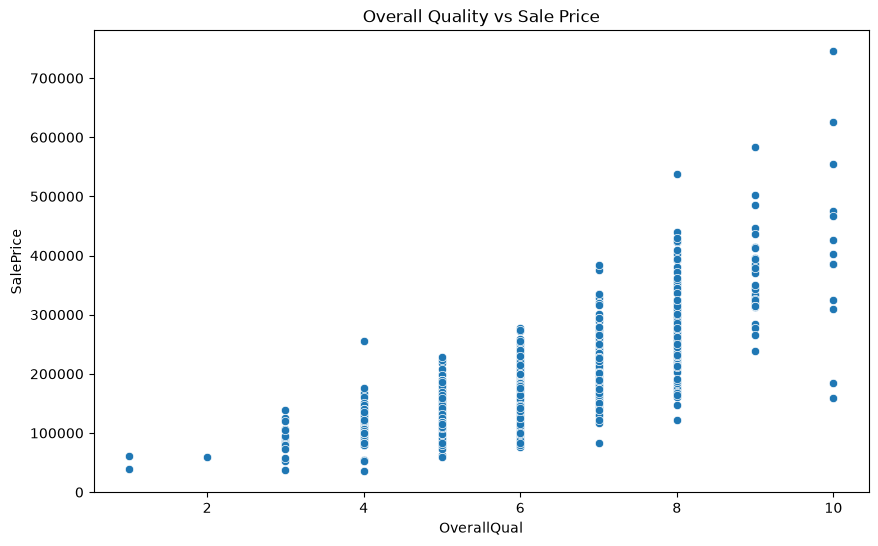

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs Sale Price")
plt.show()

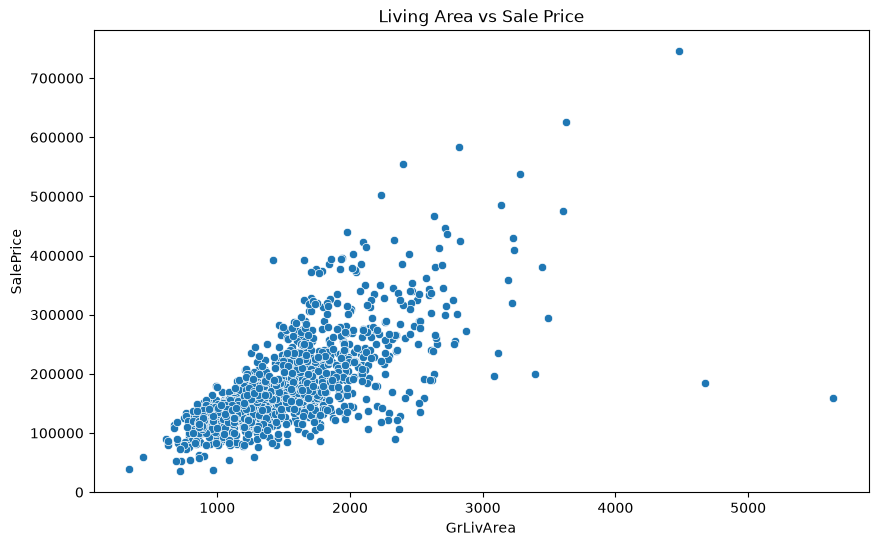

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.show()